# 02 — Liquid and gas attenuation coefficients

`kappa` comes from your own module, exactly as with real data.

For `alpha` there are two options, and the notebook keeps both:
- `alpha_*_pamtra` — PAMTRA's own gas attenuation, the truth for this dataset
- `alpha_*_own`    — your `alpha_field`, so you can check it against the truth

The retrieval in notebook 04 uses the PAMTRA values, which isolates the retrieval
algorithm from any error in your gas model. Switch with `USE_PAMTRA_ALPHA`.

In [6]:
import sys
from pathlib import Path

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

sys.path.append(str(Path("../src").resolve()))
from radar_lwc.retrieval.kappa_liquid import kappa_field
from radar_lwc.retrieval.gas_attenuation import alpha_field

DATA_DIR = Path("../data/processed/pamtra_test_1")
ds = xr.open_dataset(DATA_DIR / "pamtra_aligned.nc")

## Liquid water attenuation coefficient

In [13]:
ds.close()

In [8]:
kappa_W  = kappa_field(T_field=ds["T_cloud"], freq_ghz=94.0)
kappa_Ka = kappa_field(T_field=ds["T_cloud"], freq_ghz=35.0)

print(f"kappa_W  : {float(kappa_W.min()):.3f} - {float(kappa_W.max()):.3f}")
print(f"kappa_Ka : {float(kappa_Ka.min()):.3f} - {float(kappa_Ka.max()):.3f}")
print(f"delta    : {float((kappa_W - kappa_Ka).mean()):.3f} dB km-1 (g m-3)-1")

kappa_W  : 4.061 - 4.663
kappa_Ka : 0.719 - 0.978
delta    : 3.532 dB km-1 (g m-3)-1


## Gas attenuation: your module vs PAMTRA

`alpha_field` needs absolute humidity. PAMTRA gives relative humidity, so convert
via the Magnus saturation vapour pressure. If `RH` turned out to be all zeros in
notebook 01, this comparison is meaningless and you should simply use the PAMTRA
values — but run it anyway, because a large disagreement is itself informative.

In [9]:
def absolute_humidity(T_K, RH_frac):
    """Absolute humidity [g m-3] from temperature [K] and RH as a fraction."""
    T_C = T_K - 273.15
    e_s = 611.2 * np.exp(17.62 * T_C / (T_C + 243.12))     # Pa, over water
    return 1000.0 * RH_frac * e_s / (461.5 * T_K)

RH_frac = ds["RH"] if float(ds["RH"].max()) <= 1.5 else ds["RH"] / 100.0
AH = absolute_humidity(ds["T_cloud"], RH_frac)
AH.name = "AH"
print(f"Absolute humidity: {float(AH.min()):.3f} - {float(AH.max()):.3f} g m-3")

alpha_W_own = alpha_field(P_field=ds["P_cloud"], T_field=ds["T_cloud"],
                          AH_field=AH, freq_ghz=94.0)
alpha_Ka_own = alpha_field(P_field=ds["P_cloud"], T_field=ds["T_cloud"],
                           AH_field=AH, freq_ghz=35.0)

print(f"\nown  alpha_W  : {float(alpha_W_own.min()):.4f} - {float(alpha_W_own.max()):.4f} dB/km")
print(f"PAMTRA alpha_W: {float(ds['alpha_W_pamtra'].min()):.4f} - {float(ds['alpha_W_pamtra'].max()):.4f} dB/km")
print(f"own  alpha_Ka : {float(alpha_Ka_own.min()):.4f} - {float(alpha_Ka_own.max()):.4f} dB/km")
print(f"PAMTRA alpha_Ka: {float(ds['alpha_Ka_pamtra'].min()):.4f} - {float(ds['alpha_Ka_pamtra'].max()):.4f} dB/km")

Absolute humidity: 0.000 - 0.000 g m-3

own  alpha_W  : 0.0248 - 0.0335 dB/km
PAMTRA alpha_W: 0.0182 - 0.0437 dB/km
own  alpha_Ka : 0.0222 - 0.0309 dB/km
PAMTRA alpha_Ka: 0.0177 - 0.0425 dB/km


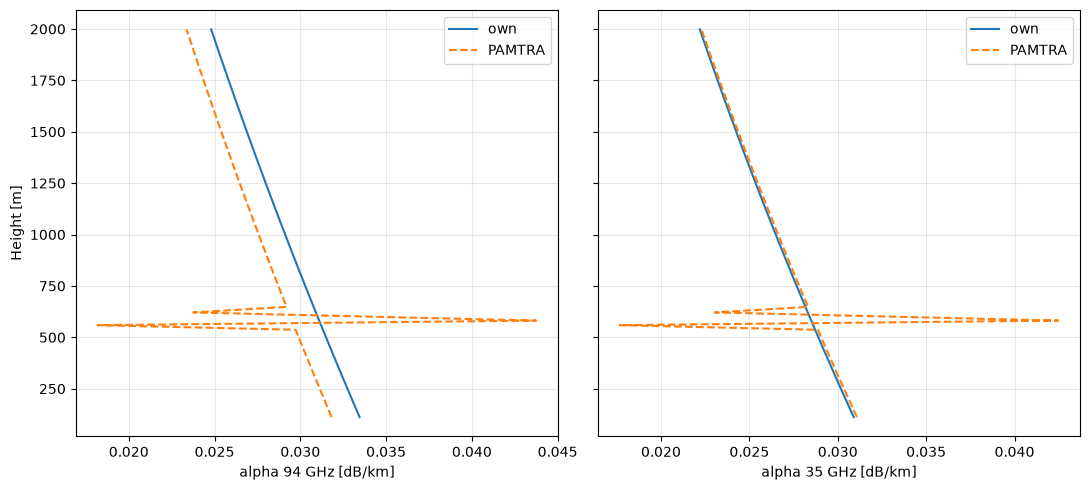

In [10]:
t = 30
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)

axes[0].plot(alpha_W_own.isel(Time=t), ds.range, label="own")
axes[0].plot(ds["alpha_W_pamtra"].isel(Time=t), ds.range, "--", label="PAMTRA")
axes[0].set_xlabel("alpha 94 GHz [dB/km]"); axes[0].set_ylabel("Height [m]")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(alpha_Ka_own.isel(Time=t), ds.range, label="own")
axes[1].plot(ds["alpha_Ka_pamtra"].isel(Time=t), ds.range, "--", label="PAMTRA")
axes[1].set_xlabel("alpha 35 GHz [dB/km]")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

## Choose which alpha feeds the retrieval

In [14]:
USE_PAMTRA_ALPHA = True

if USE_PAMTRA_ALPHA:
    alpha_W, alpha_Ka = ds["alpha_W_pamtra"], ds["alpha_Ka_pamtra"]
else:
    alpha_W, alpha_Ka = alpha_W_own, alpha_Ka_own

out = xr.Dataset({
    "kappa_W": kappa_W.rename("kappa_W"),
    "kappa_Ka": kappa_Ka.rename("kappa_Ka"),
    "alpha_W": alpha_W.rename("alpha_W"),
    "alpha_Ka": alpha_Ka.rename("alpha_Ka"),
    "alpha_W_own": alpha_W_own.rename("alpha_W_own"),
    "alpha_Ka_own": alpha_Ka_own.rename("alpha_Ka_own"),
}, attrs={"alpha_source": "PAMTRA" if USE_PAMTRA_ALPHA else "alpha_field",
          "created_by": "02_kappa_alpha.ipynb"})

out.to_netcdf(DATA_DIR / "coefficients.nc")
print("Saved -> coefficients.nc  | alpha source:", out.attrs["alpha_source"])

Saved -> coefficients.nc  | alpha source: PAMTRA
